## Error analysis — tuned Decision Tree on validation (2023)
The tuned tree's MAE is 6.64, but that is one average over 62,924 incidents. Here we split the
2023 rows into groups ("slices") to see **where** the tree is wrong, and look at real incidents.
Only training (2014–2022) and validation (2023) rows are used. **No 2024 rows.**

- `mae` = how far off the tree is in that group (minutes)
- `bias` = mean of (prediction − true): negative = the tree guesses too low, positive = too high

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

repo_root = Path.cwd().parent
sys.path.append(str(repo_root))

from src.analysis import add_delay_bucket, mae_by_group
from src.data.clean import clean_data
from src.data.split import get_split
from src.evaluate import mae
from src.features.build import add_time_features
from src.models.tree import make_decision_tree

with open(repo_root / "config" / "config.yaml") as f:
    config = yaml.safe_load(f)
SEED = config["seed"]
RESULTS = repo_root / "results"

### 1. Fit the winning tree
The settings are read from the best row of `results/tuning_tree.csv` (lowest validation MAE),
so this notebook always uses the tree the tuning picked. Fitting takes about 30 s.

In [2]:
best = pd.read_csv(RESULTS / "tuning_tree.csv").sort_values("val_mae").iloc[0]
# "no limit" is saved as the text "None", which read_csv reads back as NaN; the tree needs None
max_depth = None if pd.isna(best["max_depth"]) else int(best["max_depth"])
min_samples_leaf = int(best["min_samples_leaf"])
print(f"max_depth={max_depth}, min_samples_leaf={min_samples_leaf}")

df = clean_data(config)
train = add_time_features(get_split(df, config, "training_set"))
val = add_time_features(get_split(df, config, "validation_set"))

model = make_decision_tree(SEED, max_depth=max_depth, min_samples_leaf=min_samples_leaf)
model.fit(train.drop(columns="min_delay"), train["min_delay"])

max_depth=None, min_samples_leaf=100
Rows in 850590
dropped 39
Rows out 850551
mapped to Unknown: 65930
direction
East       192053
West       185255
North      173049
South      155067
Both        79197
Unknown     65930
Name: count, dtype: int64
Rows in 850551
dropped (missing / non-numeric / outside 1 - 999): 2849
Rows out 847702
distinct routes: 503
Rows in 847702
distinct incidents before: 36
distinct incidents after: 31
Rows out 847702
Rows in 847702
dropped total (target filter): 38020
Rows out 809682
training_set: 2014-2022, rows 683475
validation_set: 2023-2023, rows 62924


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['date','time','day',...,'month_sin','month_cos','rush_hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('route', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colu

### 2. Predict 2023 and check the overall MAE
This must match the tuning table (6.64). If it doesn't, something below is wrong.

In [3]:
res = val.copy()
res["y_true"] = res["min_delay"]
res["y_pred"] = model.predict(val.drop(columns="min_delay"))
res["abs_error"] = (res["y_pred"] - res["y_true"]).abs()
res = add_delay_bucket(res)
print(f"validation MAE: {mae(res['y_true'], res['y_pred']):.3f}  (tuning table: {best['val_mae']:.3f})")

validation MAE: 6.643  (tuning table: 6.643)


### 3. True delay size
Do short and long delays get the same error?
- n    = incidents in the group (small groups can't support strong claims)
- mae  = mean |true - pred|, how far off the model is
- bias = mean (pred - true): negative = guesses too low, positive = guesses too high

In [6]:
by_bucket = mae_by_group(res, "delay_bucket").sort_values("delay_bucket")
by_bucket

,delay_bucket,n,mae,bias
3,1-5,2974,7.068967,6.983637
5,6-10,28334,3.372725,2.408944
4,11-20,19663,4.518021,-0.689750
2,21-30,8142,8.715209,-5.460041
1,31-60,2122,17.653908,-12.868096
0,61-180,1689,61.685696,-61.626569


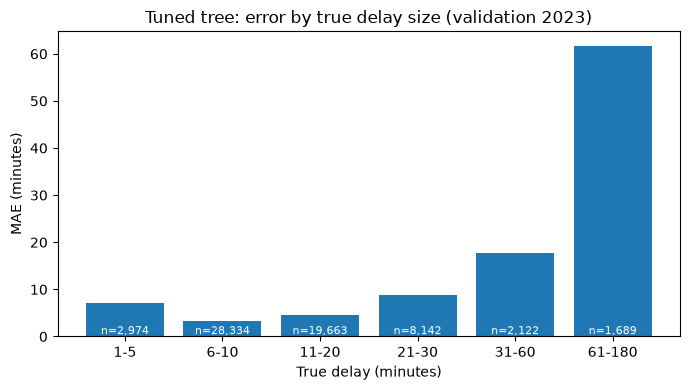

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_bucket["delay_bucket"].astype(str), by_bucket["mae"])
ax.set_xlabel("True delay (minutes)")
ax.set_ylabel("MAE (minutes)")
ax.set_title("Tuned tree: error by true delay size (validation 2023)")
for i, n in enumerate(by_bucket["n"]):
    ax.text(i, 0.5, f"n={n:,}", ha="center", color="white", fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "error_by_bucket.png", dpi=150)
plt.show()

### 4. Bus vs streetcar

In [10]:
by_mode = mae_by_group(res, "mode")
by_mode

,mode,n,mae,bias
0,streetcar,12373,8.569997,-0.718627
1,bus,50551,6.171889,-1.809968


### 10 most common incident types
Only the 10 most common, so every group has enough rows to say something.

In [11]:
top10 = res["incident"].value_counts().head(10).index
by_incident = mae_by_group(res[res["incident"].isin(top10)], "incident")
by_incident

,incident,n,mae,bias
0,Diversion,3901,33.176338,-8.621678
1,General Delay,3994,7.504067,-1.382162
2,Emergency Services,3308,5.356262,-0.705648
3,Security,4750,5.319064,-1.252207
4,Utilized Off Route,2554,4.541118,-2.762963
5,Operations,2717,4.322920,-1.708172
6,Operations - Operator,10899,4.130579,-0.452503
7,Mechanical,20258,3.858671,-1.355931
8,Collision - TTC,3419,3.850384,-0.990046
9,Cleaning - Unsanitary,3177,3.750978,-0.905514


### 6. Hour of day

In [12]:
by_hour = mae_by_group(res, "hour").sort_values("hour")
by_hour

,hour,n,mae,bias
4,0,1427,8.529436,-0.562036
6,1,927,8.183872,-0.328938
0,2,846,12.232441,-3.319717
2,3,671,9.518249,-1.869891
1,4,853,10.008670,-1.034272
7,5,2153,7.868704,-2.593012
11,6,2905,6.506710,-2.152819
14,7,2769,6.182965,-1.961107
20,8,2756,5.896013,-1.644128
18,9,3000,5.919988,-1.805629


### 7. Was this route × hour common in training?
If a route × hour pair appeared fewer than 5 times in 2014–2022, the tree has little history
for it. Counts come from the **training** rows only.

In [13]:
pair_counts = train.groupby(["route", "hour"]).size().rename("train_count")
res = res.join(pair_counts, on=["route", "hour"])
res["train_count"] = res["train_count"].fillna(0)
res["route_hour_history"] = (res["train_count"] < 5).map({True: "rare (<5 in training)", False: "common"})
by_history = mae_by_group(res, "route_hour_history")
by_history

,route_hour_history,n,mae,bias
0,rare (<5 in training),843,10.950250,0.796062
1,common,62081,6.584956,-1.627846


### 8. Save the result by group

In [14]:
slices = {
    "delay_bucket": by_bucket,
    "mode": by_mode,
    "incident_top10": by_incident,
    "hour": by_hour,
    "route_hour_history": by_history,
}
tables = []
for name, table in slices.items():
    t = table.rename(columns={table.columns[0]: "group"}).copy()
    t["group"] = t["group"].astype(str)
    t.insert(0, "slice", name)
    tables.append(t)
pd.concat(tables).to_csv(RESULTS / "error_by_group.csv", index=False)
print("saved results/error_by_group.csv")

saved results/error_by_group.csv


### 9. Case studies — real incidents
For each, we count how many 2023 incidents
match, then show 3 picked at random (seed 42), not the most extreme ones, so the examples are
typical of the category.

In [15]:
worst_incident = by_incident.iloc[0]["incident"]  # highest MAE among the top 10
categories = {
    "Long delay, under-predicted (true > 60, error > 40)":
        (res["y_true"] > 60) & (res["abs_error"] > 40),
    "Short delay, over-predicted (true <= 5, prediction >= 12)":
        (res["y_true"] <= 5) & (res["y_pred"] >= 12),
    "Rare route x hour (< 5 in training)":
        res["train_count"] < 5,
    f"Hardest incident type ({worst_incident})":
        res["incident"] == worst_incident,
    "Overnight (hour 0-4)":
        res["hour"] <= 4,
}
show = ["date", "time", "mode", "route", "incident", "location", "direction", "y_true", "y_pred"]
case_rows = []
for name, mask in categories.items():
    group = res[mask]
    print(f"\n{name}: {len(group):,} incidents, MAE {group['abs_error'].mean():.2f}")
    sample = group.sample(n=min(3, len(group)), random_state=SEED)[show].round(1)
    display(sample)
    case_rows.append(sample.assign(category=name))
pd.concat(case_rows).to_csv(RESULTS / "case_studies.csv", index=False)
print("saved results/case_studies.csv")


Long delay, under-predicted (true > 60, error > 40): 1,194 incidents, MAE 77.24


,date,time,mode,route,incident,location,direction,y_true,y_pred
621067,2023-08-20,10:45,bus,9,Diversion,BELLEAMY AND PROGRESS,Unknown,84.0,36.8
626448,2023-09-21,17:51,bus,165,Diversion,WESTON AND ORMONT DR,East,105.0,37.3
629555,2023-10-09,14:21,bus,19,Diversion,BAY AND QUEEN,South,120.0,39.6



Short delay, over-predicted (true <= 5, prediction >= 12): 918 incidents, MAE 15.22


,date,time,mode,route,incident,location,direction,y_true,y_pred
827873,2023-06-01,18:52,streetcar,505,Security,QUEEN AND BOULTEN,West,3.0,12.9
592194,2023-02-02,10:44,bus,134,Operations - Operator,SCARBOROUGH CENTRE STA,Unknown,5.0,17.0
630521,2023-10-14,18:34,bus,29,General Delay,NOVA SCOTIA AND PRINCE,North,5.0,16.0



Rare route x hour (< 5 in training): 843 incidents, MAE 10.95


,date,time,mode,route,incident,location,direction,y_true,y_pred
633544,2023-10-31,18:52,bus,903,Mechanical,MIDLAND AND EGLINTON,West,2.0,11.8
618176,2023-08-02,01:17,bus,14,Emergency Services,CHAPLIN AND EGLINTON,West,31.0,19.7
639966,2023-12-07,04:16,bus,925,Operations - Operator,EGLINGTON DIVISION,North,10.0,9.3



Hardest incident type (Diversion): 3,901 incidents, MAE 33.18


,date,time,mode,route,incident,location,direction,y_true,y_pred
606705,2023-05-19,07:54,bus,121,Diversion,ESPLANADE AND PRINCESS,Unknown,65.0,45.9
826175,2023-04-19,23:55,streetcar,510,Diversion,SPADINA STATION,Unknown,10.0,39.9
626803,2023-09-24,02:00,bus,335,Diversion,EGLINTON AND JANE,South,81.0,71.8



Overnight (hour 0-4): 4,724 incidents, MAE 9.53


,date,time,mode,route,incident,location,direction,y_true,y_pred
591735,2023-01-30,03:04,bus,336,Collision - TTC,FINCH AND MARTIN GROVE,East,30.0,31.0
639961,2023-12-07,03:50,bus,339,General Delay,FINCH AND ALAMOSA DRIV,East,20.0,30.6
835884,2023-12-21,03:01,streetcar,504,Operations,RONCESVALLES AND QUEEN,South,10.0,12.4


saved results/case_studies.csv


### 10. What I noticed
1. **Delay size.** Best on 6–10 min delays (MAE 3.4), the most common kind. Worst on 61–180 min
   (MAE 61.7). Short delays are guessed too high and long ones too low, probably because each
   leaf predicts an average, which sits in the middle.
2. **Bus vs streetcar.** Streetcar is harder (8.6 vs 6.2). There are about 4× fewer streetcar incidents to learn from.
3. **Incident type.** Diversion is by far the hardest (33.2; the next is 7.5). How long a diversion
   lasts is probably not known when it is logged.
4. **Hour.** About 6 in the daytime, 8–12 late at night, when there are fewer incidents to learn from.
5. **Rare route × hour.** Worse (11.0 vs 6.6), but only 843 incidents (1.3%), so a small effect.
6. **Case studies.**
   - Long delays guessed too low: all 3 are diversions (84–120 min, predicted about 40).
   - Short delays guessed too high: 3–5 min predicted at 13–17. A leaf median (X3) might help.
   - Rare route × hour: express and night routes; errors go both ways.
   - Diversions: one lasted 10 min, others over an hour. One label covers very different lengths.
   - Overnight: errors are bigger than in the day, but not extreme.

These are patterns in 2023 only. They show where the tree is wrong